# Analysis of Sotorasib Response Data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import sys
import os
from itertools import product
from tqdm import tqdm

sys.path.append("./utils/")
from drc_utils import load_drc_data, bootstrap_DRC_fit

# Set up the plotting environment
sns.set(style="white", 
        font='Gill Sans')

In [4]:
### Notebook parameters
results_df_all = pd.read_excel("Raw data -Sotorasib DRC data.xlsx")

# Parameterise DRC fitting
n_bootstraps = 100
model = "ll4_log"
significance_level_ci = 0.95
from_scratch = True

treatment_palette = {"Parental": sns.xkcd_rgb["black"], "Osimertinib": sns.xkcd_rgb["purple"], 
                     "DMSO": sns.xkcd_rgb["sea green"], "Untreated": sns.xkcd_rgb["grey"]}
replicate_palette = {'D1-m': sns.xkcd_rgb["dusty blue"], 'D2-m': sns.xkcd_rgb["steel grey"],
                        'R1-m': sns.xkcd_rgb["violet"], 'R2-m': sns.xkcd_rgb["teal green"], 'R3-m': sns.xkcd_rgb["orange"], 
                        'R4-m': sns.xkcd_rgb["plum"], 'R5-m': sns.xkcd_rgb["lightish blue"], 'R6-m': sns.xkcd_rgb["pink red"]}
cycle_palette = {0:"black", 5: sns.xkcd_rgb["slate blue"], 6: sns.xkcd_rgb["sky blue"], 
                 10: sns.xkcd_rgb["dark blue"], 11: sns.xkcd_rgb["denim blue"], 21: sns.xkcd_rgb["navy"]}

## Assemble data

In [3]:
file_name = "Raw data -Sotorasib DRC data.xlsx"
layout_file_dict = {"manual": "plateLayout_sotorasib.xlsx", 
               "hamilton": "plateLayout_sotorasib_hamilton.xlsx"}
# Get all the sheet names in the excel sheet
sheet_names_list = pd.ExcelFile(os.path.join(file_name)).sheet_names
tmp_list = []
for sheet in tqdm(sheet_names_list):
    # Choose the layout file to use
    method = "manual" # experimental method; most were done manually
    if ("first" in sheet) or ("second" in sheet) or (sheet in ["Sheet41", "Sheet42"]):
        method = "hamilton"
    # Load the data
    tmp_df = load_drc_data(fname=os.path.join(file_name), layout_file=layout_file_dict[method], 
                           sheet_num=sheet, sheet_prefix=None,
                           drug_names = ["Sotorasib"], max_concentrations = [2], 
                           cell_type_names = ["H358"], 
                           machine = "jinling", negative_control="AB", drop_control = True, 
                           normalise_by = "mean", detailed_output=False)
    
    # There were some reads that were faulty/inconsistent. Decided to exclude these for the "cleaned" dataset
    tmp_df["Viability_cleaned"] = tmp_df["Viability"]
    tmp_df["ReplicateId_technical"] = tmp_df.RowId.apply(lambda x: {"B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6}[x])
    tmp_df['Method'] = method
    tmp_df["SheetName"] = sheet

    # Grab meta-data
    if sheet != "C0":
        if "(" in sheet:
            sheet = sheet.split(" (")[0]
        cycle_id = int(sheet.split(" ")[0][1:])
        replicate_name = sheet.split(" ")[1]
        replicate_id = int(''.join(ch for ch in replicate_name if ch.isdigit()))
        experimental_arm = "treatment" if "R" in replicate_name else "control"
        
        if replicate_name == "D2-m_2":
            # this is a second plate that jinling made for the biospa but didn't use. instead she ran it as an extra replicate,
            # so it should be the same as the other run. Label these as replicates 7-12
            tmp_df["ReplicateId_technical"] += 6
            replicate_name = "D2-m"
        if "second" in sheet: 
            # the hamilton runs were spread out across 2 plates; account for that by
            # labeling plate 1 reps 1-3 and plate 2 reps 4-6.
            tmp_df["ReplicateId_technical"] += 3

        # Add meta-data to the dataframe
        tmp_df['CycleId'] = cycle_id
        tmp_df['Replicate'] = replicate_id
        tmp_df['ReplicateName'] = replicate_name
        tmp_df['ExperimentalArm'] = experimental_arm
        tmp_list.append(tmp_df)
    else: 
        # For the baseline, add it once to each replicate
        for replicate_name in ['D1-m', 'D2-m', 'R1-m', 'R2-m', 'R3-m', 'R4-m', 'R5-m', 'R6-m']:
            tmp_df['CycleId'] = 0
            tmp_df['Replicate'] = int(replicate_name[1])
            tmp_df['ReplicateName'] = replicate_name
            tmp_df['ExperimentalArm'] = "treatment" if "R" in replicate_name else "control"
            tmp_list.append(tmp_df.copy())
results_df_all = pd.concat(tmp_list, axis=0)

# Detect outliers and remove them using an IQR filter (within 2.22 IQR (equiv. to z-score < 3))
def detect_outliers_iqr(data):
    # Adopted from: https://stackoverflow.com/questions/23199796/detect-and-exclude-outliers-in-a-pandas-dataframe
    # Very robust method for outlier detection. Used in sklearn's RobustScaler.
    Q1 = data.quantile(0.25, interpolation="nearest")
    Q3 = data.quantile(0.75, interpolation="nearest")
    IQR = Q3 - Q1
    # In a normal distribution, we have roughly iqr=1.35*s, so to translate z=3 of a z-score filter, we do
    # 3s = 3/1.35*iqr to get the f in the iqr filter.
    f = 3 / 1.35
    return np.abs((data - data.median()) / IQR) > f # corresponds to 3 standard deviations in a normal distribution

def detect_outliers_manual(data, drug_concentration, method="manual"):
    greater_than_max = data > 135 # Remove anything with more than 135% viability, as it's likely an error
    too_much_survival = data > 200
    if drug_concentration > 1: # For the higher concentrations, we expect little to no survival, so remove anything above 50%
        too_much_survival = data > 50
    return greater_than_max | too_much_survival

# Apply the outlier detection
tmp_list = []
for _, df in results_df_all.groupby(["ReplicateName", "CycleId", "DrugConcentration"]):
    iqr = detect_outliers_iqr(df["Fluorescence_raw"])
    manual = detect_outliers_manual(df["Viability_cleaned"], df["DrugConcentration"].unique()[0])
    df["IsOutlier"] = iqr | manual
    tmp_list.append(df)
results_df_all = pd.concat(tmp_list, axis=0)
results_df_all['Viability_cleaned'] = results_df_all['Viability_cleaned'].where(~results_df_all['IsOutlier'], np.nan)
results_df_all.loc[results_df_all['SheetName'].isin(["Sheet43", "Sheet44"]), 'Viability_cleaned'] = np.nan # Drop the 5h reads since the scaled results are the same as at 3h, and we use 3h incubation everywhere else

# Save
results_df_all.to_csv(os.path.join("sotorasib_cleaned.csv"))
results_df_all.head()

100%|███████████████████████████████████████████| 84/84 [00:14<00:00,  5.68it/s]
/Users/wuj15/miniforge3/envs/jupyter/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,RowId,ColumnId,Drug,WellId,DrugConcentration,Fluorescence_raw,CellType,Fluorescence_normalised,Viability,Machine,Viability_cleaned,ReplicateId_technical,Method,SheetName,CycleId,Replicate,ReplicateName,ExperimentalArm,IsOutlier
89,B,12,Sotorasib,B12,0.0,11313.0,H358,1.047621,104.762077,jinling,104.762077,1,manual,C0,0,1,D1-m,control,False
90,C,12,Sotorasib,C12,0.0,10635.0,H358,0.974074,97.407434,jinling,97.407434,2,manual,C0,0,1,D1-m,control,False
91,D,12,Sotorasib,D12,0.0,10324.0,H358,0.940338,94.033844,jinling,94.033844,3,manual,C0,0,1,D1-m,control,False
92,E,12,Sotorasib,E12,0.0,10852.0,H358,0.997614,99.761354,jinling,99.761354,4,manual,C0,0,1,D1-m,control,False
93,F,12,Sotorasib,F12,0.0,10796.0,H358,0.991539,99.153891,jinling,99.153891,5,manual,C0,0,1,D1-m,control,False


### Outlier detection and removal

/Users/wuj15/miniforge3/envs/jupyter/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


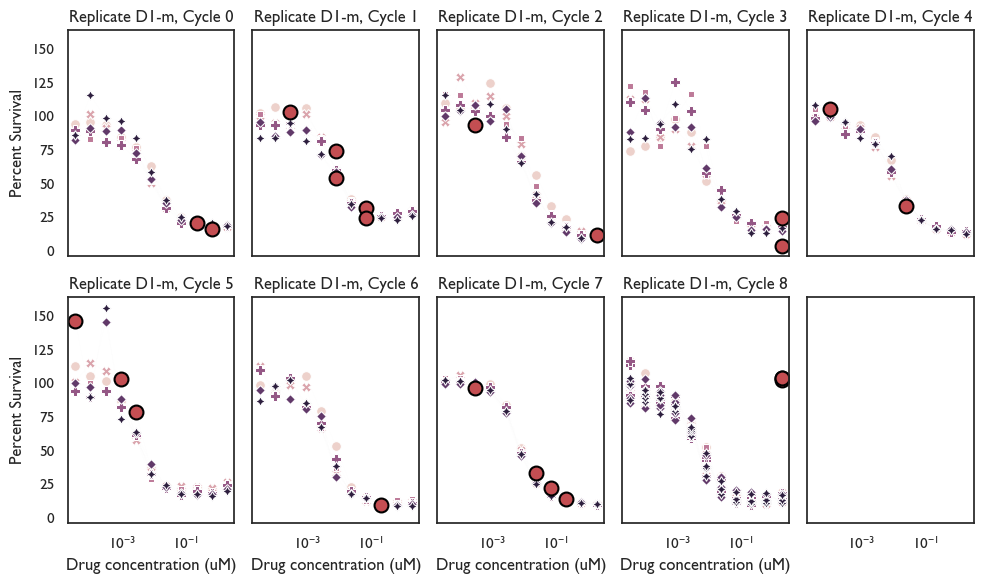

In [4]:
# Apply the outlier detection
tmp_list = []
results_df_all = pd.read_csv(os.path.join("sotorasib_cleaned.csv"), index_col=0)
data_df = results_df_all
for _, df in data_df.groupby(["ReplicateName", "CycleId", "DrugConcentration"]):
    df["IsOutlier"] = detect_outliers_iqr(df["Fluorescence_raw"])
    tmp_list.append(df)
results_df_all = pd.concat(tmp_list, axis=0)

# Plot the data for each replicate separately
# for replicate_name in results_df_all.ReplicateName.unique():
replicate_name = "D1-m"
fig, ax_list = plt.subplots(2, 5, sharex=True, sharey=True, figsize=(10, 6))
for cycle_id in range(9):
    ax = ax_list.flatten()[cycle_id]
    data_df = results_df_all[(results_df_all.ReplicateName==replicate_name) & (results_df_all.CycleId==cycle_id)]
    data_df = data_df[(data_df.DrugConcentration > 0)]
    # Plot the data
    sns.lineplot(x="DrugConcentration", y="Viability", style="ReplicateId_technical", hue="ReplicateId_technical", estimator=None,
                err_style="bars", errorbar='sd',
                markers=True, markersize=7, linewidth=0.001,
                legend=False, 
                data=data_df, ax=ax)
    # Annotate outliers
    ax.plot(data_df[data_df["IsOutlier"]]["DrugConcentration"], data_df[data_df["IsOutlier"]]["Viability"], 
            'ro', markersize=10, markeredgecolor="black", markeredgewidth=1.5)
    # Decorate
    ax.set_xscale('log')
    ax.set_xlabel("Drug concentration (uM)")
    ax.set_ylabel("Percent Survival")
    ax.set_title("Replicate %s, Cycle %d" % (replicate_name, cycle_id))
plt.tight_layout()
plt.savefig("./figures/sotorasib_drc_%s.pdf" % replicate_name)

## Plot by replicate

/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3931044434.py:8: UserWarning: 
The palette list has fewer values (9) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(x="DrugConcentration", y="Viability_cleaned", style="CycleId", hue="CycleId", estimator="median",
/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3931044434.py:8: UserWarning: 
The palette list has fewer values (9) than needed (11) and will cycle, which may produce an uninterpretable plot.
  sns.lineplot(x="DrugConcentration", y="Viability_cleaned", style="CycleId", hue="CycleId", estimator="median",


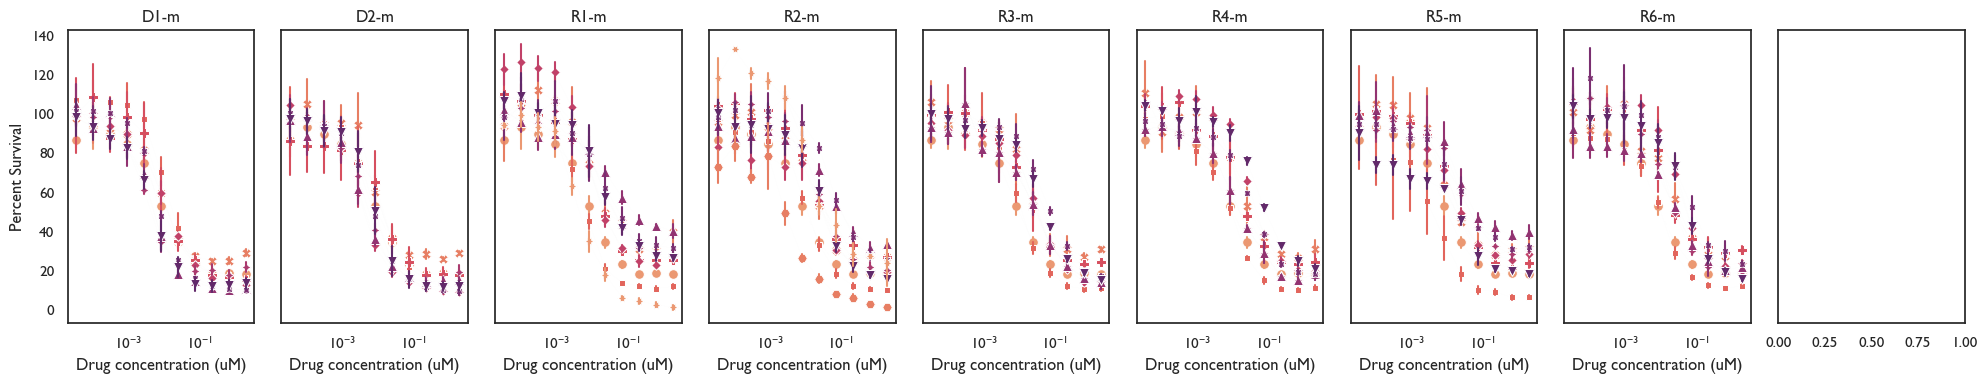

In [5]:
# Plot the data for each cell line separately
fig, ax_list = plt.subplots(1, 9, sharey=True, figsize=(20, 4))
for i, replicate_name in enumerate(results_df_all.ReplicateName.unique()):
    ax = ax_list.flatten()[i]
    data_df = results_df_all[(results_df_all.ReplicateName==replicate_name)]
    data_df = data_df[(data_df.DrugConcentration > 0) & ~data_df.Viability_cleaned.isna()]
    # Plot the data
    sns.lineplot(x="DrugConcentration", y="Viability_cleaned", style="CycleId", hue="CycleId", estimator="median",
                err_style="bars", errorbar='sd',
                markers=True, markersize=7, linewidth=0.001,
                legend=False, palette=sns.color_palette("flare", 9),
                data=data_df, ax=ax)
    ax.set_xscale('log')
    ax.set_xlabel("Drug concentration (uM)")
    ax.set_ylabel("Percent Survival")
    ax.set_title(replicate_name)
plt.tight_layout()

## Fit a log-logistic model

In [13]:
# Load data
results_df_all = pd.read_csv(os.path.join("sotorasib_cleaned.csv"), index_col=0)
results_df_all.ReplicateName.unique()

array(['D1-m', 'D2-m', 'R1-m', 'R2-m', 'R3-m', 'R4-m', 'R5-m', 'R6-m'],
      dtype=object)

### Example

/Users/wuj15/Documents/Alamar Blue/./utils/drc_utils.py:152: UserWarning: The 0 concentration was removed from the data to allow fitting of the dose ll4_log model
  warnings.warn("The 0 concentration was removed from the data to allow fitting of the dose {} model".format(model))
/Users/wuj15/Documents/Alamar Blue/./utils/drc_utils.py:158: UserWarning: NaN values were found in the data. Dropping these values.
  warnings.warn("NaN values were found in the data. Dropping these values.")
100%|█████████████████████████████████████████| 100/100 [00:03<00:00, 26.74it/s]


<Axes: xlabel='DrugConcentration', ylabel='Viability_cleaned'>

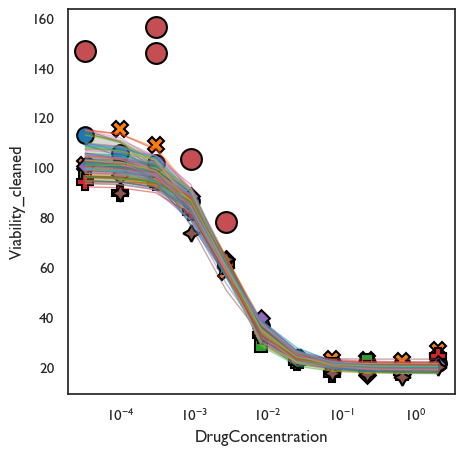

In [14]:
n_bootstraps_example = 100

# Load data for an example cell line and drug
example_df = results_df_all[(results_df_all.ReplicateName=="D1-m") & (results_df_all.CycleId==5)]
example_df = example_df.reset_index(drop=True)

# Plot the raw data
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sns.lineplot(x="DrugConcentration", y="Viability_cleaned", style="ReplicateId_technical", hue="ReplicateId_technical", estimator=None,
            err_style="bars", errorbar='sd',
            markers=True, markersize=12, palette="tab10", markeredgecolor="black", markeredgewidth=1.5,
            linewidth=0.001,
            legend=False, 
            data=example_df, ax=ax)
# Annotate outliers
ax.plot(example_df[example_df["IsOutlier"]]["DrugConcentration"], example_df[example_df["IsOutlier"]]["Viability"], 
        'ro', markersize=15, markeredgecolor="black", markeredgewidth=1.5)
ax.set_xscale('log')

# Fit the DRC
param_df, prediction_df, param_df_bootstrap, prediction_df_bootstrap = bootstrap_DRC_fit(data_df=example_df, model="ll4_log", x="DrugConcentration", y="Viability_cleaned", 
                                            bounds_list = (0, [150, 50, 10, 50]), n_boot=n_bootstraps_example, significance_level_ci=0.95, 
                                            return_bootstrap=True, plot_bootstraps=False)

# Plot the fit
sns.lineplot(x="DrugConcentration", y="Viability_cleaned", 
            color=sns.xkcd_rgb["teal"], linewidth=3, 
            data=prediction_df,
            ax=ax)

# Plot the confidence intervals
ax.fill_between(prediction_df["DrugConcentration"], prediction_df["LowerCI"], prediction_df["UpperCI"], color="grey", alpha=0.3)

# # Plot the individual bootstraps
sns.lineplot(x="DrugConcentration", y="Viability_cleaned", hue="BootstrapId", estimator=None,
             palette="tab10", linewidth=1., alpha=0.5,
             legend=False,
             data=prediction_df_bootstrap, ax=ax)

### Compute dose-response characteristics for all data

In [15]:
data_dir = "./"
# Fit the DRC for all cell lines and drugs
from_scratch = True
os.makedirs(os.path.join("drcs"), exist_ok=True)

for i, curr_df in tqdm(list(results_df_all.groupby(["ReplicateName", "CycleId"]))):
    # Pre-process the data
    curr_df = curr_df[curr_df.DrugConcentration > 0].copy()  # Remove the 0 concentration points
    curr_df = curr_df.dropna(subset=["Viability_cleaned"])   # Remove the NaN values
    cycle_id = curr_df.CycleId.values[0]

    # Check if we already fitted this drc
    if (not from_scratch) and (
        os.path.exists(
            os.path.join(
                data_dir,
                "drcs",
                "collateral_assays_%s_%s_%s_%d_%d.csv" % (
                    "params",
                    curr_df["ReplicateName"].values[0],
                    curr_df["Drug"].values[0],
                    cycle_id,
                    n_bootstraps
                )
            )
        )
    ):
        continue

    # If we don’t see more than 50% kill in the data, force the lower bound for the IC50 to be beyond the maximum concentration
    # e_max, e_min, b, ic50
    lower_bound_list = [0] * 4
    upper_bound_list = [150, 100, 25, np.max(curr_df.DrugConcentration) * 5]
    p0 = [100, np.max([np.min(curr_df.Viability_cleaned), 0]), 1, np.max(curr_df.DrugConcentration) / 2]

    if np.min(curr_df.Viability_cleaned) > 50:
        lower_bound_list = [0, 0, 0, np.max(curr_df.DrugConcentration) * 0.8]
        p0[-1] = np.max(curr_df.DrugConcentration)

    # Fit the DRC
    param_df, prediction_df, param_df_bootstrap, prediction_df_bootstrap = bootstrap_DRC_fit(
        data_df=curr_df,
        model="ll4_log",
        x="DrugConcentration",
        y="Viability_cleaned",
        bounds_list=(lower_bound_list, upper_bound_list),
        p0=p0,
        n_boot=n_bootstraps,
        significance_level_ci=significance_level_ci,
        return_bootstrap=True,
        show_progress=False
    )

    # Annotate the results
    for x in [param_df, prediction_df, param_df_bootstrap, prediction_df_bootstrap]:
        x["ReplicateName"] = curr_df["ReplicateName"].values[0]
        x["CycleId"] = curr_df["CycleId"].values[0]
        x["Drug"] = curr_df["Drug"].values[0]

    # Save results to file
    for df, name in zip(
        [param_df, prediction_df, param_df_bootstrap, prediction_df_bootstrap],
        ["params", "fit", "params_bootstrap", "fit_bootstrap"]
    ):
        df.to_csv(
            os.path.join(
                data_dir,
                "drcs",
                "collateral_assays_%s_%s_%s_%d_%d.csv" % (
                    name,
                    curr_df["ReplicateName"].values[0],
                    curr_df["Drug"].values[0],
                    cycle_id,
                    n_bootstraps
                )
            )
        )

# Concatenate the results
for name in ["params", "fit", "params_bootstrap", "fit_bootstrap"]:
    tmp_list = []
    for file in os.listdir(os.path.join(data_dir, "drcs")):
        if (name in file) and (name + "_b" not in file) and (str(n_bootstraps) in file):
            tmp_list.append(pd.read_csv(os.path.join(data_dir, "drcs", file), index_col=0))
    pd.concat(tmp_list).to_csv(os.path.join(data_dir, "sotorasib_drc_%s.csv" % name))

# Load the results
params_df = pd.read_csv(os.path.join("sotorasib_drc_params.csv"), index_col=0)
fit_df = pd.read_csv(os.path.join("sotorasib_drc_fit.csv"), index_col=0)
params_df_bootstraps = pd.read_csv(os.path.join("sotorasib_drc_params_bootstrap.csv"), index_col=0)
fit_df_bootstraps = pd.read_csv(os.path.join("sotorasib_drc_fit_bootstrap.csv"), index_col=0)

100%|███████████████████████████████████████████| 75/75 [04:35<00:00,  3.67s/it]


### Plot fits

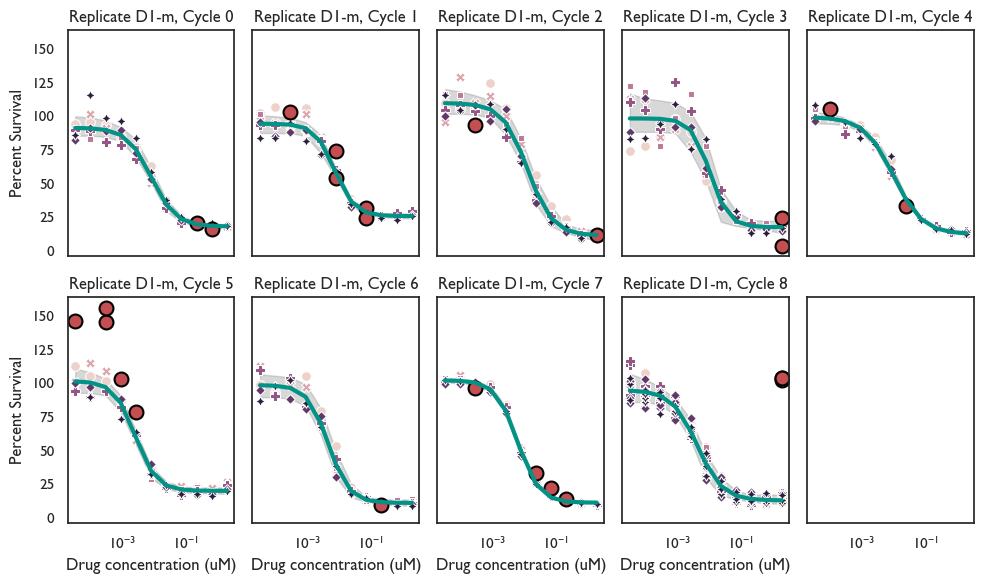

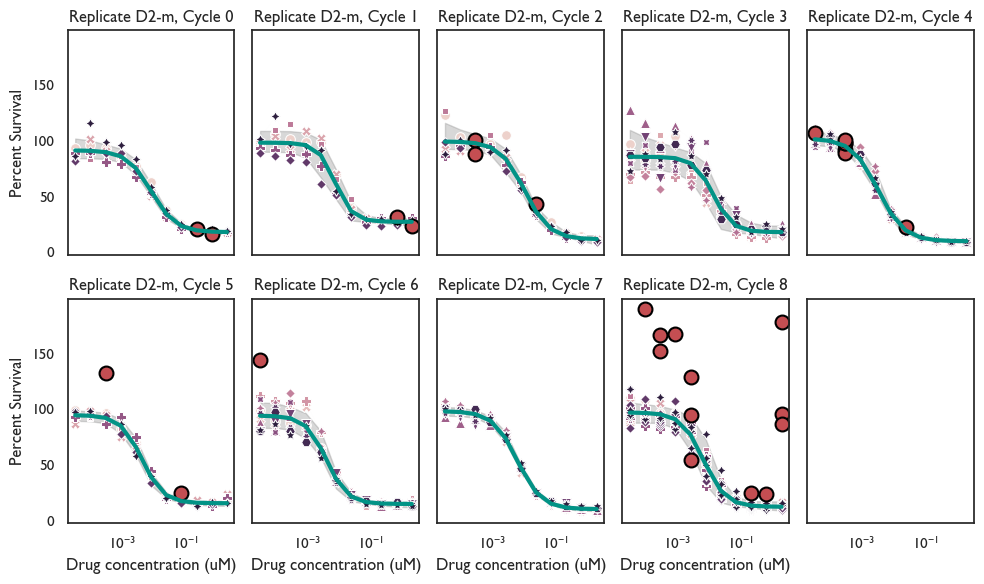

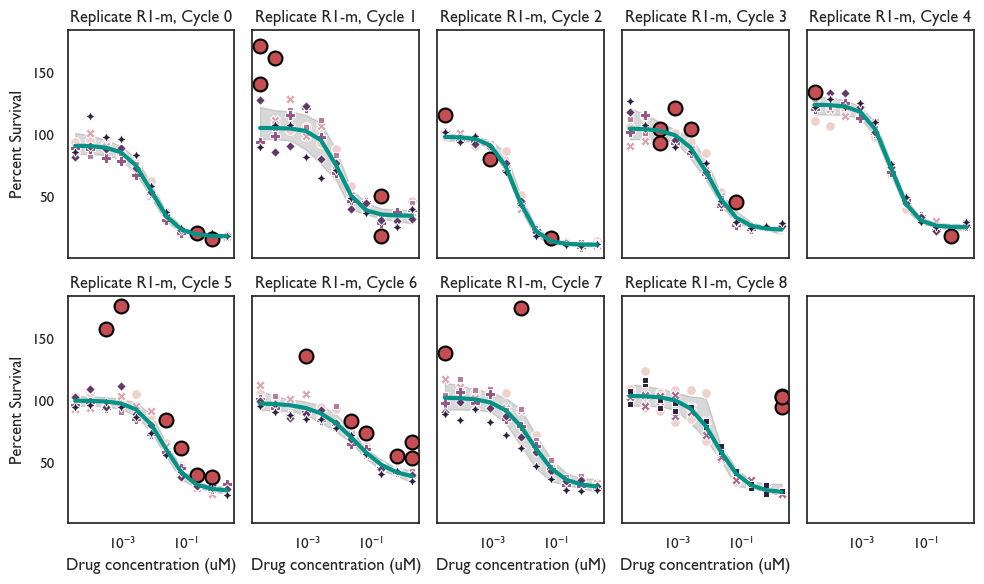

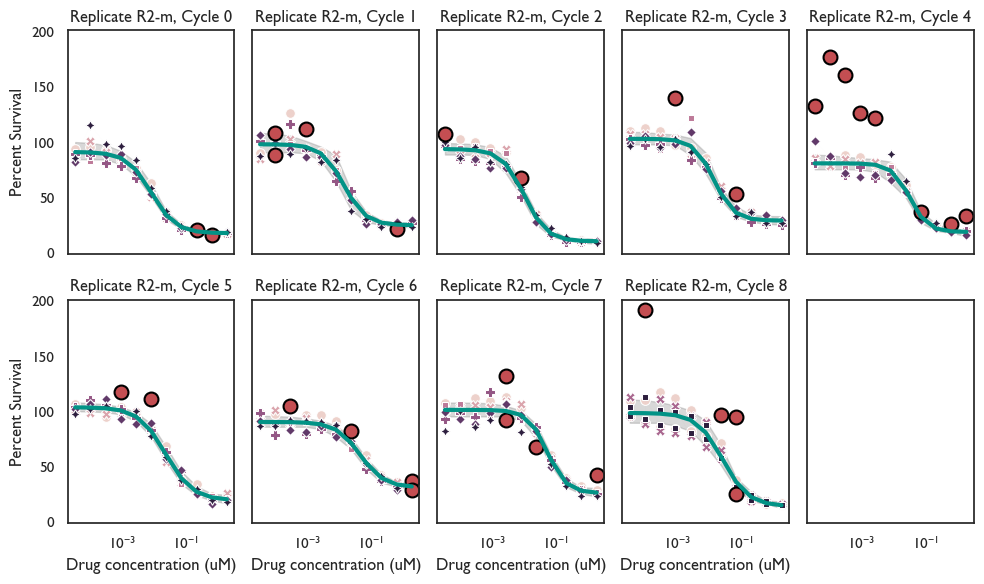

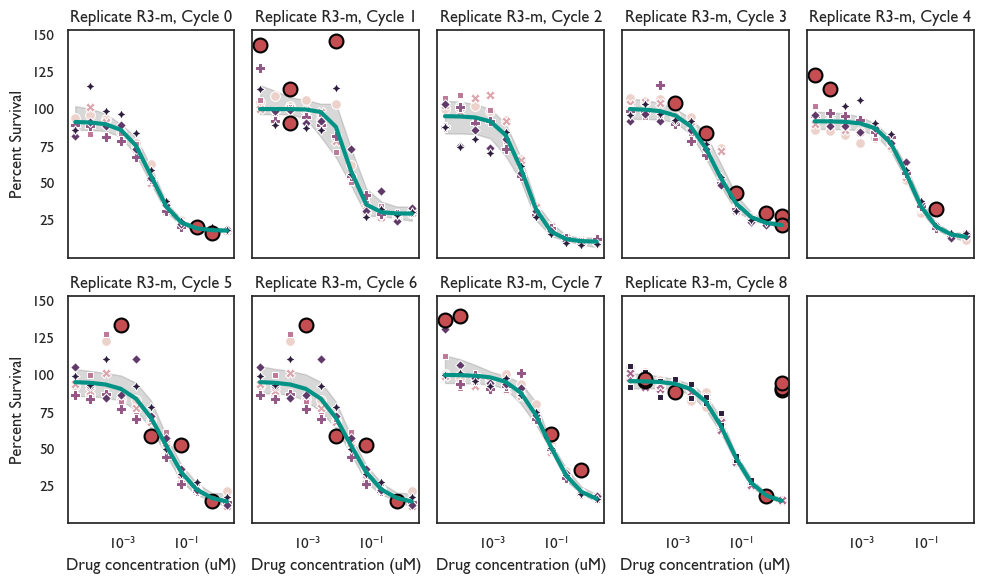

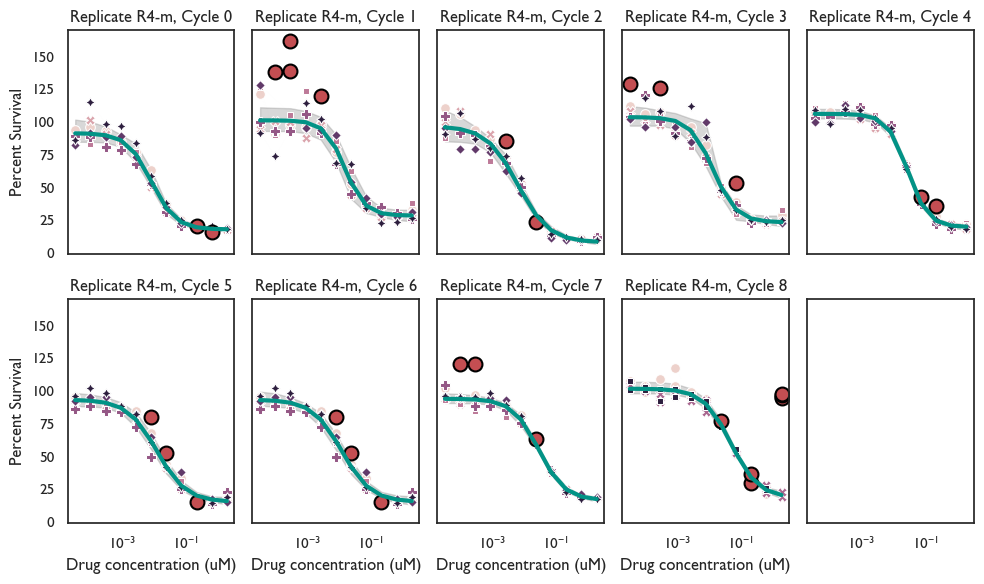

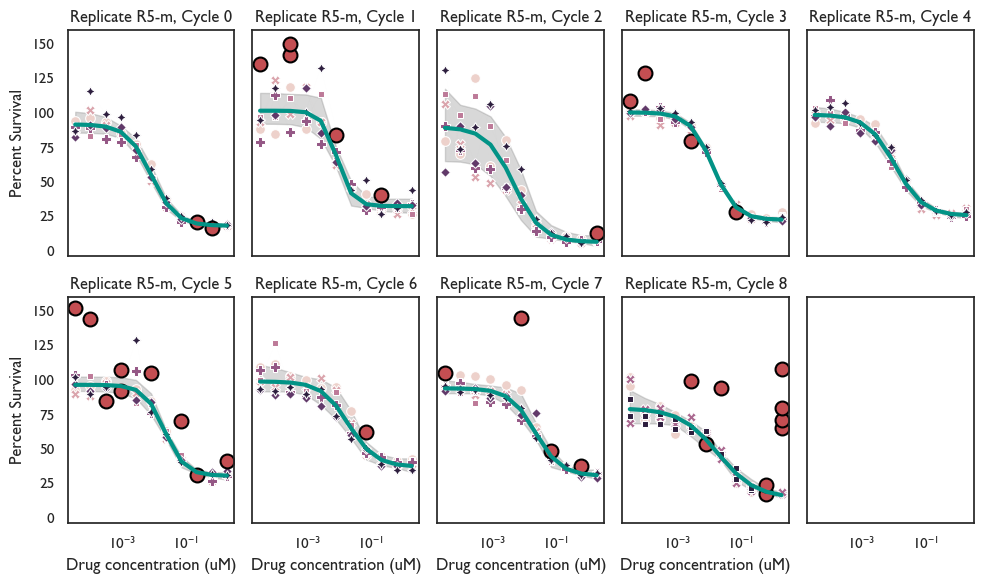

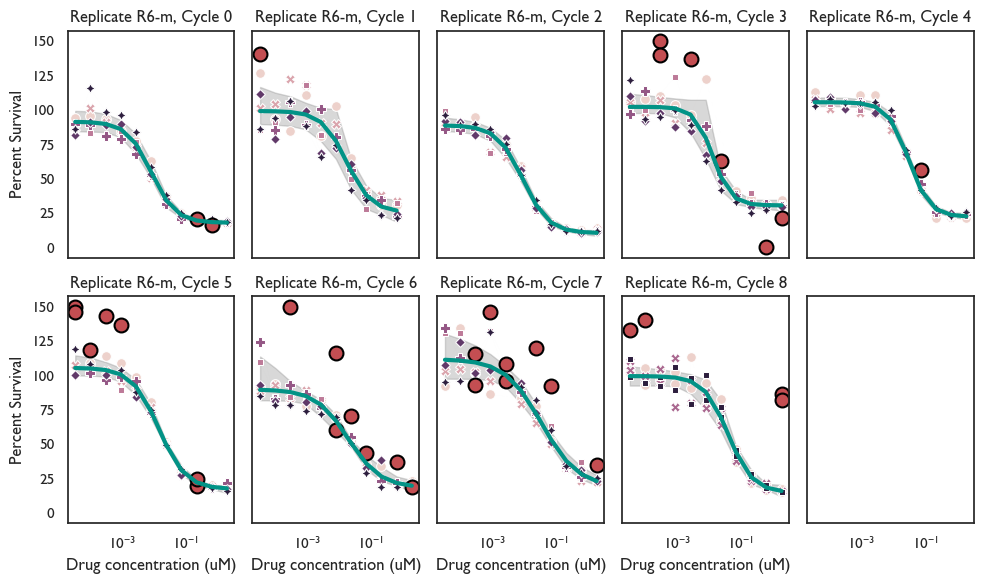

In [16]:
# Load data
fit_df = pd.read_csv(os.path.join("sotorasib_drc_fit.csv"), index_col=0)

# Plot the data for each replicate separately
for replicate_name in results_df_all.ReplicateName.unique():
    fig, ax_list = plt.subplots(2, 5, sharex=True, sharey=True, figsize=(10, 6))
    for cycle_id in range(9):
        ax = ax_list.flatten()[cycle_id]
        data_df = results_df_all[(results_df_all.ReplicateName==replicate_name) & (results_df_all.CycleId==cycle_id)]
        data_df = data_df[(data_df.DrugConcentration > 0)]
        # Plot the data
        sns.lineplot(x="DrugConcentration", y="Viability_cleaned", style="ReplicateId_technical", hue="ReplicateId_technical", estimator=None,
                    err_style="bars", errorbar='sd',
                    markers=True, markersize=7, linewidth=0.001,
                    legend=False, 
                    data=data_df[~data_df.Viability_cleaned.isna()], ax=ax)
        # Annotate outliers
        ax.plot(data_df[data_df["IsOutlier"]]["DrugConcentration"], data_df[data_df["IsOutlier"]]["Viability"], 
                'ro', markersize=10, markeredgecolor="black", markeredgewidth=1.5)
        # Plot the fit
        prediction_df = fit_df[(fit_df.ReplicateName==replicate_name) & (fit_df.CycleId==cycle_id)]
        sns.lineplot(x="DrugConcentration", y="Viability_cleaned", 
                    color=sns.xkcd_rgb["teal"], linewidth=3, 
                    data=prediction_df,
                    ax=ax)
        # Plot the confidence intervals
        ax.fill_between(prediction_df["DrugConcentration"], prediction_df["LowerCI"], prediction_df["UpperCI"], color="grey", alpha=0.3)
        # Decorate
        ax.set_xscale('log')
        ax.set_xlabel("Drug concentration (uM)")
        ax.set_ylabel("Percent Survival")
        ax.set_title("Replicate %s, Cycle %d" % (replicate_name, cycle_id))
    plt.tight_layout()
    plt.savefig("./figures/sotorasib_drc_%s.pdf" % replicate_name)

## Analyse dose-response metrics

In [19]:
# Load drc fitting results
params_df = pd.read_csv(os.path.join(data_dir, "sotorasib_drc_params.csv"), index_col=0)
fit_df = pd.read_csv(os.path.join(data_dir, "sotorasib_drc_fit.csv"), index_col=0)
params_df_bootstraps = pd.read_csv(os.path.join(data_dir, "sotorasib_drc_params_bootstrap.csv"), index_col=0)
fit_df_bootstraps = pd.read_csv(os.path.join(data_dir, "sotorasib_drc_fit_bootstrap.csv"), index_col=0)

# Plotting params
plotting_order = list(range(9)) + [11] + [21]

# Annotate if the parameters are significantly different from the controls
for parameter in ["ic50", "e_max", "e_min", "b", "auc"]:
    # Calculate the 95% confidence intervals for the control samples across technical and evolutionary replicates and across time.
    ic50_pre = params_df_bootstraps[(np.isin(params_df_bootstraps.ReplicateName, ["D1-m", "D2-m"])) & (params_df_bootstraps.Parameter==parameter)].Value
    lower_CI = ic50_pre.quantile((1-significance_level_ci)/2)
    upper_CI = ic50_pre.quantile((1 + significance_level_ci)/2)

    for i, curr_df in params_df_bootstraps[params_df_bootstraps["Parameter"]==parameter].groupby(["ReplicateName", "CycleId"]):
        curr_ci = np.array([[curr_df["Value"].quantile((1-significance_level_ci)/2)], [curr_df["Value"].quantile((1 + significance_level_ci)/2)]])
        no_overlap = (curr_ci[1] < lower_CI) or (curr_ci[0] > upper_CI)
        params_df.loc[(params_df["ReplicateName"]==i[0]) & (params_df["CycleId"]==i[1]) & (params_df["Parameter"]==parameter), "StatDifferent"] = no_overlap

In [20]:
params_df[(params_df.Parameter=="ic50") & (params_df.CycleId==21)]

,Parameter,MLE,LowerCI,UpperCI,ReplicateName,CycleId,Drug,StatDifferent
3,ic50,0.005003,0.004030,0.006534,R1-m,21,Sotorasib,False
3,ic50,0.004337,0.001774,0.005725,R2-m,21,Sotorasib,False


In [60]:
params_df[(params_df.Parameter=="ic50") & (params_df.CycleId==0)]

,Parameter,MLE,LowerCI,UpperCI,ReplicateName,CycleId,Drug,StatDifferent
3,ic50,0.008339,0.005259,0.011238,R1-m,0,Sotorasib,False
3,ic50,0.008339,0.005212,0.011280,R3-m,0,Sotorasib,False
3,ic50,0.008339,0.004949,0.011859,D2-m,0,Sotorasib,False
3,ic50,0.008339,0.005576,0.011726,R5-m,0,Sotorasib,False
3,ic50,0.008339,0.006019,0.011730,R2-m,0,Sotorasib,False
3,ic50,0.008339,0.005047,0.012184,R4-m,0,Sotorasib,False
3,ic50,0.008339,0.005531,0.011419,R6-m,0,Sotorasib,False
3,ic50,0.008339,0.006232,0.011625,D1-m,0,Sotorasib,False


In [21]:
params_df[(params_df.Parameter=="ic50") & (params_df.CycleId==11)]

,Parameter,MLE,LowerCI,UpperCI,ReplicateName,CycleId,Drug,StatDifferent
3,ic50,0.011501,0.008598,0.015707,R2-m,11,Sotorasib,False


In [22]:
params_df[
    (params_df.Parameter == "ic50") &
    (params_df.ReplicateName.isin(["R1-m", "R2-m"])) &
    (params_df.CycleId.isin([0, 8, 11, 21]))
]

,Parameter,MLE,LowerCI,UpperCI,ReplicateName,CycleId,Drug,StatDifferent
3,ic50,0.008339,0.005259,0.011238,R1-m,0,Sotorasib,False
3,ic50,0.011501,0.008598,0.015707,R2-m,11,Sotorasib,False
3,ic50,0.018225,0.008792,0.024335,R1-m,8,Sotorasib,False
3,ic50,0.005003,0.004030,0.006534,R1-m,21,Sotorasib,False
3,ic50,0.028202,0.014779,0.039338,R2-m,8,Sotorasib,False
3,ic50,0.004337,0.001774,0.005725,R2-m,21,Sotorasib,False
3,ic50,0.008339,0.006019,0.011730,R2-m,0,Sotorasib,False


### Plot DRCs over cycles

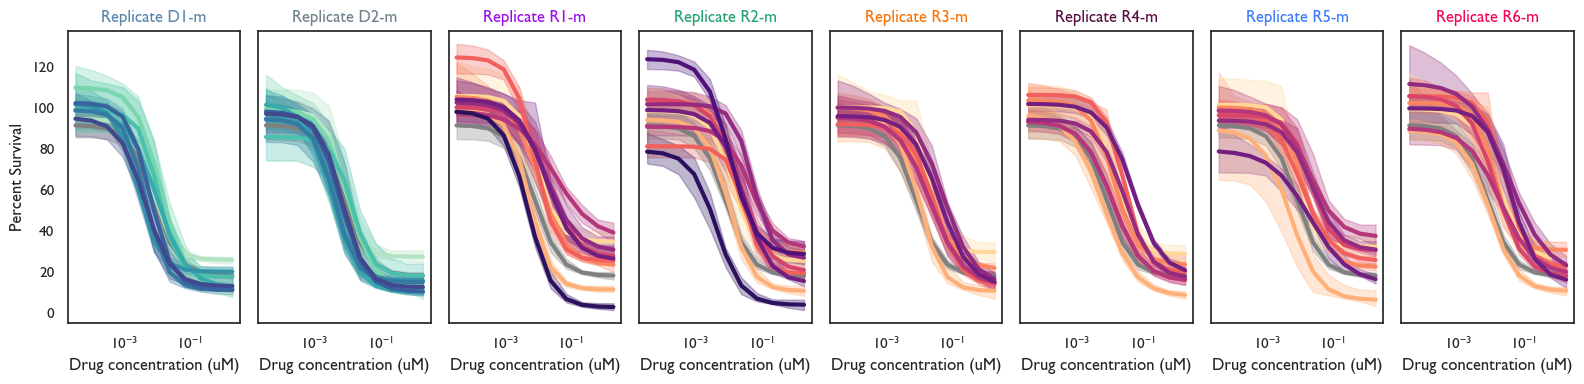

In [23]:
# Plot the data for each replicate separately
fig, ax_list = plt.subplots(1, 8, sharex=True, sharey=True, figsize=(16, 4))
replicate_list = ['D1-m', 'D2-m', 'R1-m', 'R2-m', 'R3-m', 'R4-m', 'R5-m', 'R6-m']
for i, replicate_name in enumerate(replicate_list):
    ax = ax_list.flatten()[i]
    # Plot the fit
    prediction_df = fit_df[(fit_df.ReplicateName==replicate_name)]
    treatment_arm = results_df_all[results_df_all.ReplicateName==replicate_name].ExperimentalArm.unique()[0]
    curr_palette = "mako_r" if treatment_arm=="control" else "magma_r"
    curr_palette = {0: "grey", **{x: sns.color_palette(curr_palette, 11)[i] for i, x in enumerate([1,2,3,4,5,6,7,8,11,21])}}
    sns.lineplot(x="DrugConcentration", y="Viability_cleaned", hue="CycleId", 
                linewidth=3, palette=curr_palette,
                data=prediction_df,
                legend=False,
                ax=ax)
    # Plot the confidence intervals
    for cycle_id in prediction_df.CycleId.unique():
        curr_df = prediction_df[prediction_df.CycleId==cycle_id]
        ax.fill_between(curr_df["DrugConcentration"], curr_df["LowerCI"], curr_df["UpperCI"], color=curr_palette[cycle_id], alpha=0.3)
    # ax.fill_between(prediction_df["DrugConcentration"], prediction_df["LowerCI"], prediction_df["UpperCI"], color="grey", alpha=0.3)
    # Decorate
    ax.set_xscale('log')
    ax.set_xlabel("Drug concentration (uM)")
    ax.set_ylabel("Percent Survival")
    ax.set_title("Replicate %s"%replicate_name, color=replicate_palette[replicate_name])
plt.tight_layout()
plt.savefig("./figures/sotorasib_drc_overview.pdf")

### Plot comparison for one drug along with fitted DRCs

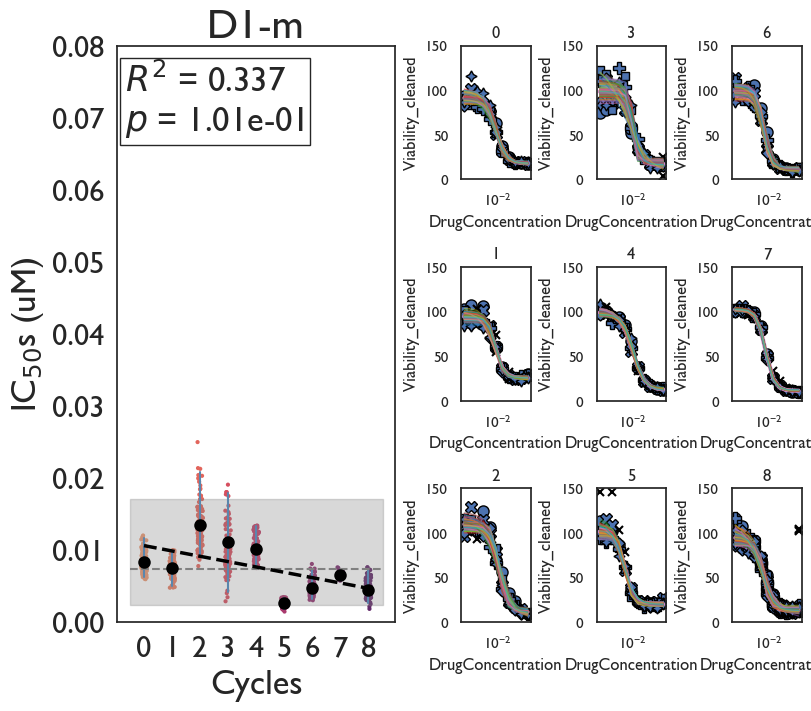

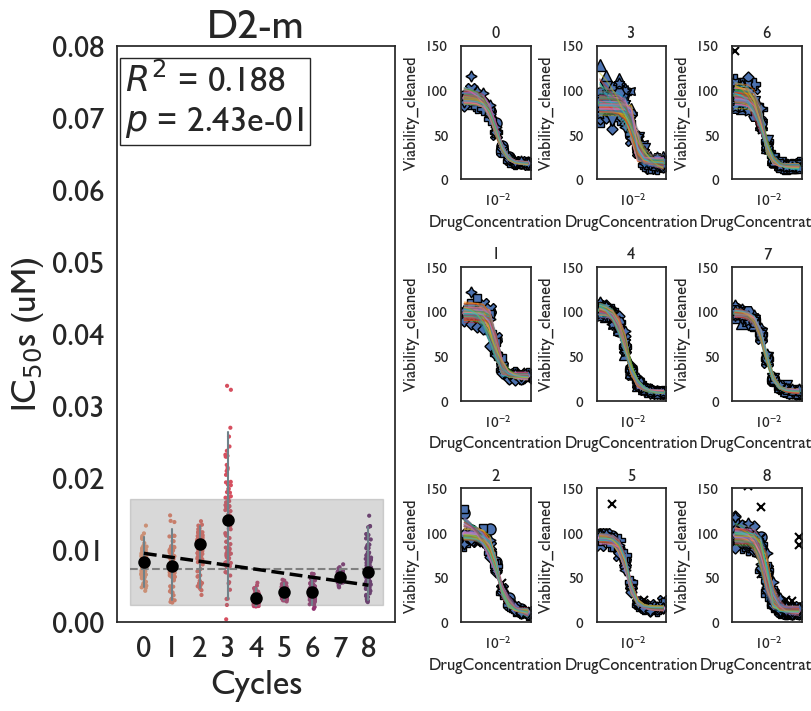

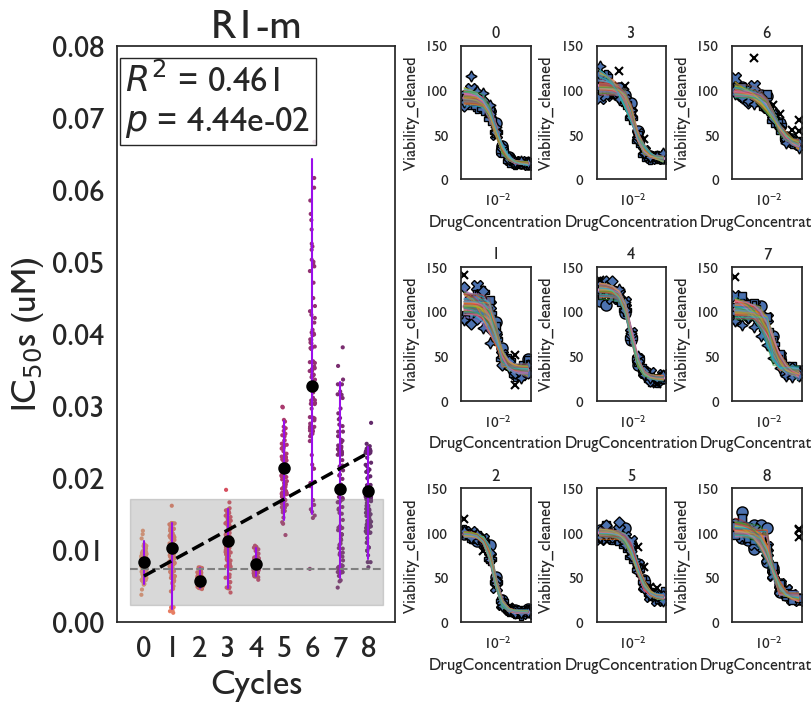

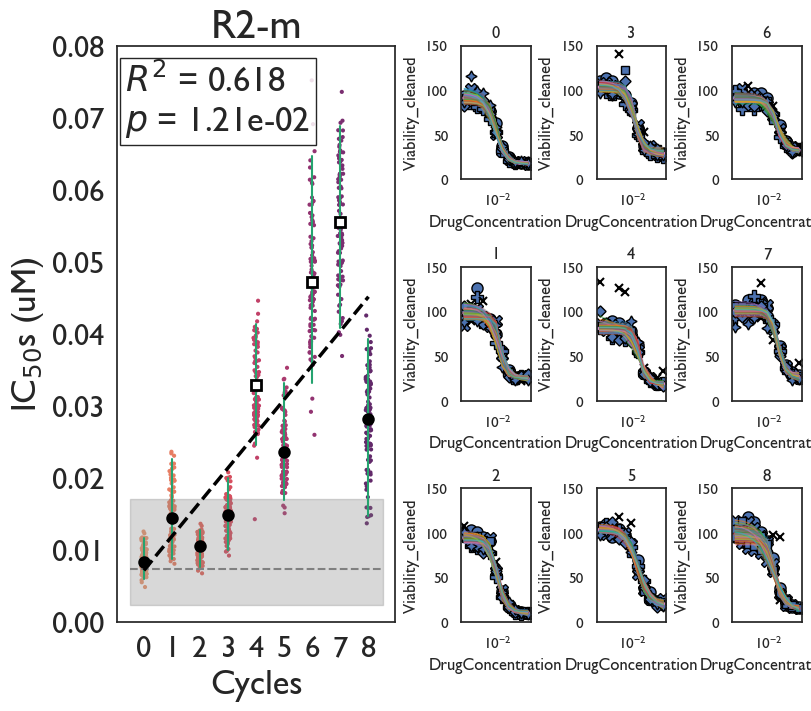

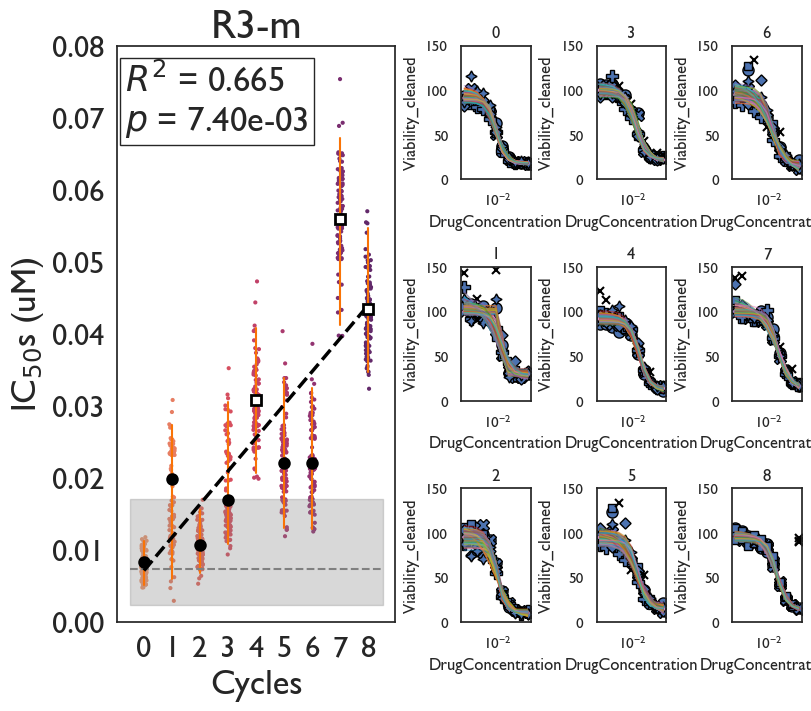

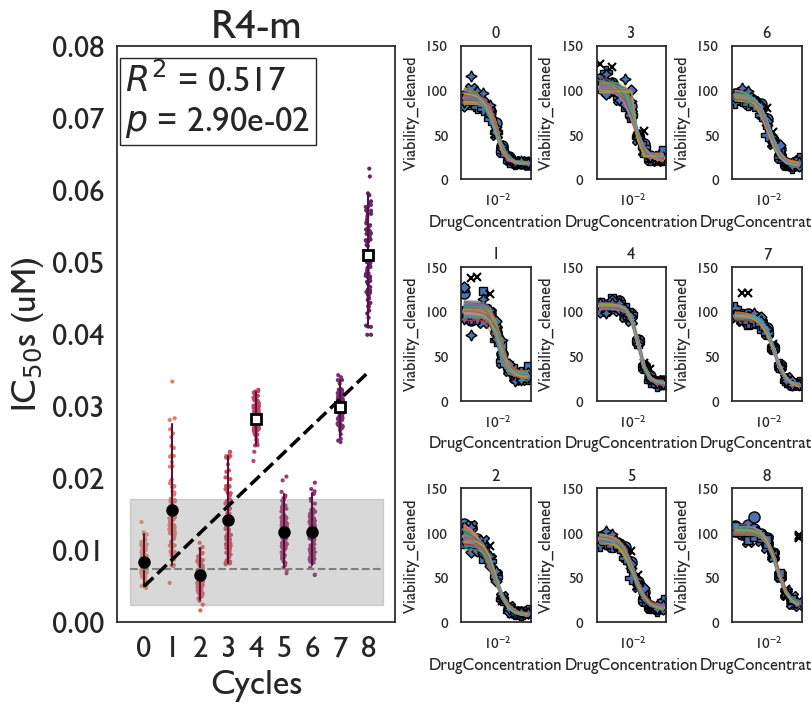

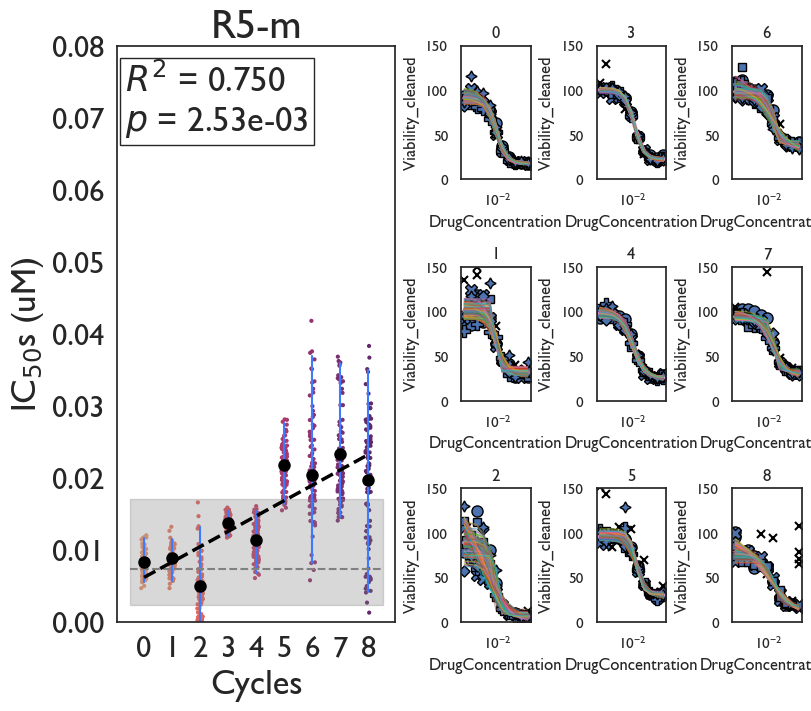

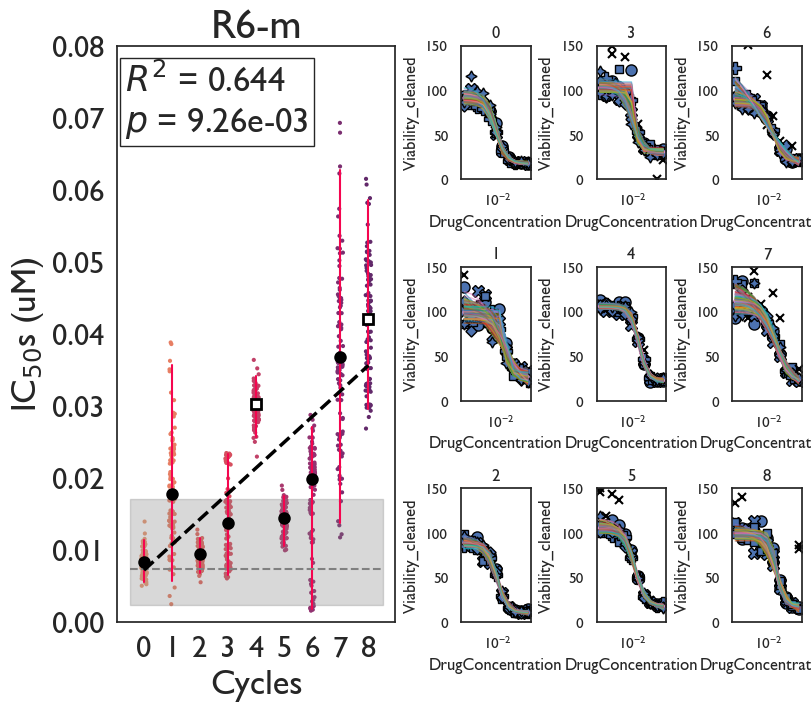

In [104]:
from scipy.stats import linregress  # NEW

replicate_name = "D1-m"
parameter = "ic50"

# Only plot Cycles 0–8 in this section
plotting_order = list(range(9))

color_palette = sns.color_palette("flare", len(plotting_order))
palette = {
    x: color_palette[i]
    for i, x in enumerate(plotting_order)
}

# We will overlay a grey band indicating the 95% CI of where
# the untreated controls fall. Calculate that interval here.
ic50_pre = params_df_bootstraps[
    (np.isin(
        params_df_bootstraps.ReplicateName,
        ["D1-m", "D2-m"]
    )) &
    (params_df_bootstraps.Parameter == parameter) &
    (params_df_bootstraps.CycleId.isin(plotting_order))
].Value

lower_CI = ic50_pre.quantile(
    (1 - significance_level_ci) / 2
)

upper_CI = ic50_pre.quantile(
    (1 + significance_level_ci) / 2
)


for replicate_name in results_df_all.ReplicateName.unique():

    fig, ax_list = plt.subplot_mosaic(
        [
            [
                "left",
                "right%d" % x,
                "right%d" % (x + 3),
                "right%d" % (x + 6)
            ]
            for x in range(3)
        ],
        figsize=(8, 7),
        layout="constrained",
        gridspec_kw={
            "width_ratios": [1, 1/4, 1/4, 1/4]
        }
    )

    # ---------------------------------------------------------------------
    # Plot the IC50s
    ax = ax_list["left"]

    # Bootstrap samples for Cycles 0–8
    curr_df = params_df_bootstraps[
        (params_df_bootstraps.Parameter == parameter) &
        (params_df_bootstraps.ReplicateName == replicate_name) &
        (params_df_bootstraps.CycleId.isin(plotting_order))
    ].copy()

    curr_df = curr_df.reset_index()

    # MLE estimates for Cycles 0–8
    mle_df = params_df[
        (params_df.ReplicateName == replicate_name) &
        (params_df.Parameter == parameter) &
        (params_df.CycleId.isin(plotting_order))
    ].copy()

    # Plot the MLE estimate for the parameter and annotate if it is
    # significantly different from the control lines
    sns.pointplot(
        x="CycleId",
        y="MLE",
        hue="StatDifferent",
        order=plotting_order,
        linestyles="none",
        markers=["o", "s"],
        markersize=7,
        markeredgewidth=2,
        markeredgecolor="black",
        palette={
            True: "white",
            False: "black"
        },
        zorder=10,
        data=mle_df,
        ax=ax
    )

    # Plot the 95% CI for each cell line
    # based on the bootstrap samples
    sns.pointplot(
        x="CycleId",
        y="Value",
        errorbar=lambda x: np.array([
            [
                x.quantile(
                    (1 - significance_level_ci) / 2
                )
            ],
            [
                x.quantile(
                    (1 + significance_level_ci) / 2
                )
            ]
        ]),
        err_kws={
            "linewidth": 1.5
        },
        order=plotting_order,
        color=replicate_palette[replicate_name],
        markers="o",
        markersize=0,
        linestyle="none",
        data=curr_df,
        ax=ax
    )

    # Overlay the bootstrap points
    sns.stripplot(
        x="CycleId",
        y="Value",
        hue="CycleId",
        size=3,
        order=plotting_order,
        hue_order=plotting_order,
        palette=palette,
        data=curr_df,
        ax=ax,
        zorder=0
    )

    # ---------------------------------------------------------------------
    # Fit linear regression to the MLE estimates from Cycles 0–8
    regression_df = (
        mle_df
        .groupby("CycleId", as_index=False)["MLE"]
        .mean()
        .dropna()
        .sort_values("CycleId")
    )

    if regression_df["CycleId"].nunique() >= 2:

        slope, intercept, r_value, p_value, std_err = linregress(
            regression_df["CycleId"],
            regression_df["MLE"]
        )

        regression_x = np.array(plotting_order)
        regression_y = intercept + slope * regression_x

        # Black regression line
        ax.plot(
            regression_x,
            regression_y,
            color="black",
            linewidth=2.5,
            zorder=8,
            linestyle="--"
        )

        # Display R-squared and slope p-value
        ax.text(
            0.03,
            0.97,
            (
                rf"$R^2$ = {r_value**2:.3f}"
                "\n"
                rf"$p$ = {p_value:.2e}"
            ),
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=25,
            bbox={
                "facecolor": "white",
                "edgecolor": "black",
                "alpha": 0.85
            }
        )

    # Overlay band indicating 95% CI of where the pre-treatment
    # IC50 values were, combining the two control lines
    x_lims = ax.get_xlim()

    ax.fill_between(
        x_lims,
        lower_CI,
        upper_CI,
        color="grey",
        alpha=0.3
    )

    ax.hlines(
        xmin=x_lims[0],
        xmax=x_lims[1],
        y=ic50_pre.mean(),
        color="grey",
        linestyle="--"
    )

    # Decorate the left panel
    ax.legend().remove()

    ax.set_title(
        replicate_name,
        fontsize=30
    )

    ax.set_xlabel(
        "Cycles",
        fontsize=25
    )

    ax.set_ylabel(
        r"IC$_{50}$s (uM)",
        fontsize=25
    )

    ax.tick_params(
        axis="both",
        labelsize=22
    )

    ax.set_ylim(0, 8e-2)

    # ---------------------------------------------------------------------
    # Plot the DRCs
    for i, cycle_id in enumerate(plotting_order):

        ax = ax_list["right%d" % i]

        curr_df = results_df_all[
            (results_df_all.ReplicateName == replicate_name) &
            (results_df_all.CycleId == cycle_id)
        ]

        curr_df = curr_df[
            curr_df.DrugConcentration > 0
        ]

        if len(curr_df) == 0:
            continue

        # Plot the data
        sns.lineplot(
            x="DrugConcentration",
            y="Viability_cleaned",
            hue="ReplicateName",
            style="ReplicateId_technical",
            estimator=None,
            err_style="bars",
            errorbar="sd",
            markers=True,
            markersize=8,
            linewidth=0.001,
            markeredgewidth=1,
            markeredgecolor="black",
            legend=False,
            data=curr_df[
                ~curr_df.Viability_cleaned.isna()
            ],
            ax=ax
        )

        # Overlay outliers
        ax.plot(
            curr_df[curr_df["IsOutlier"]]["DrugConcentration"],
            curr_df[curr_df["IsOutlier"]]["Viability"],
            "rx",
            markersize=6,
            markeredgecolor="black",
            markeredgewidth=1.5
        )

        # Plot the fits
        prediction_df = fit_df[
            (fit_df.ReplicateName == replicate_name) &
            (fit_df.CycleId == cycle_id)
        ]

        sns.lineplot(
            x="DrugConcentration",
            y="Viability_cleaned",
            linewidth=3,
            data=prediction_df,
            ax=ax
        )

        # Plot the confidence intervals
        ax.fill_between(
            prediction_df["DrugConcentration"],
            prediction_df["LowerCI"],
            prediction_df["UpperCI"],
            color="grey",
            alpha=0.3
        )

        # Plot the bootstrap fits
        prediction_df = fit_df_bootstraps[
            (fit_df_bootstraps.ReplicateName == replicate_name) &
            (fit_df_bootstraps.CycleId == cycle_id)
        ]

        sns.lineplot(
            x="DrugConcentration",
            y="Viability_cleaned",
            hue="BootstrapId",
            estimator=None,
            palette="tab10",
            linewidth=1,
            alpha=0.5,
            legend=False,
            data=prediction_df,
            ax=ax
        )

        ax.set_xscale("log")
        ax.set_title(cycle_id)
        ax.set_ylim(0, 150)

    plt.savefig(
        "./figures/sotorasib_C0to8_%s_%s.pdf"
        % (parameter, replicate_name)
    )

    plt.savefig(
        "./figures/sotorasib_C0to8_%s_%s.png"
        % (parameter, replicate_name), dpi=1200
    )

### Compare across cycle and evolutionary replicate

/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:46: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[7.6 0.6 1.6 2.6 5.6 6.6 4.6 3.6]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  curr_df.loc[
/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6
 

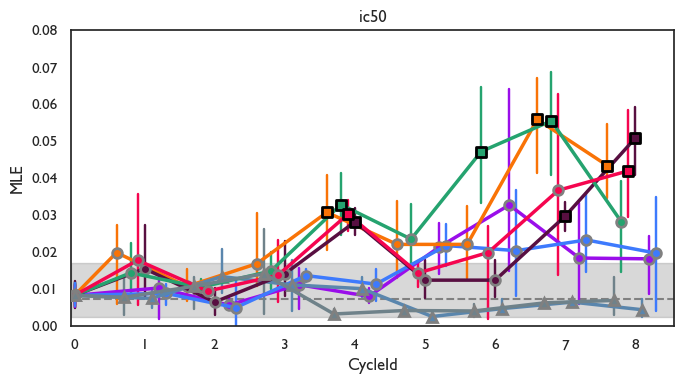

/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:46: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[7.6 0.6 1.6 2.6 5.6 6.6 4.6 3.6]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  curr_df.loc[
/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6
 

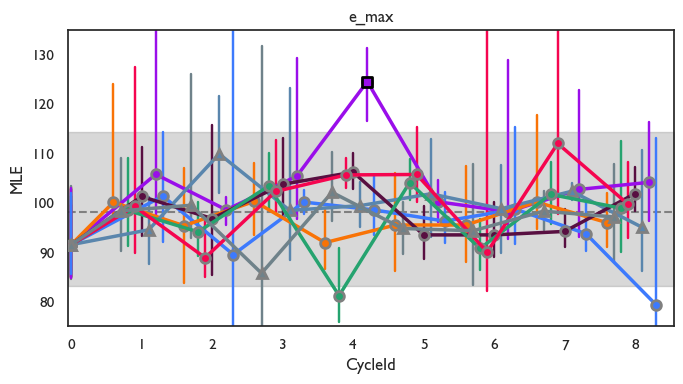

/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:46: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[7.6 0.6 1.6 2.6 5.6 6.6 4.6 3.6]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  curr_df.loc[
/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6
 

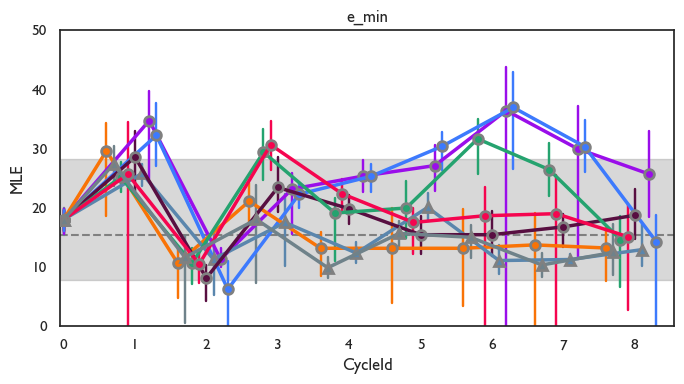

/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:46: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[7.6 0.6 1.6 2.6 5.6 6.6 4.6 3.6]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  curr_df.loc[
/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6
 

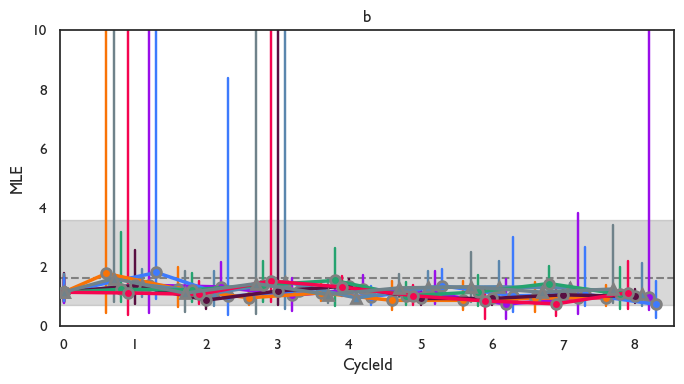

/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:46: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[7.6 0.6 1.6 2.6 5.6 6.6 4.6 3.6]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  curr_df.loc[
/var/folders/xn/xt9bh7qj6zl9bds2n_nbn3gjpqq95f/T/ipykernel_97075/3378472349.py:52: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6
 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 5.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6 6.6
 

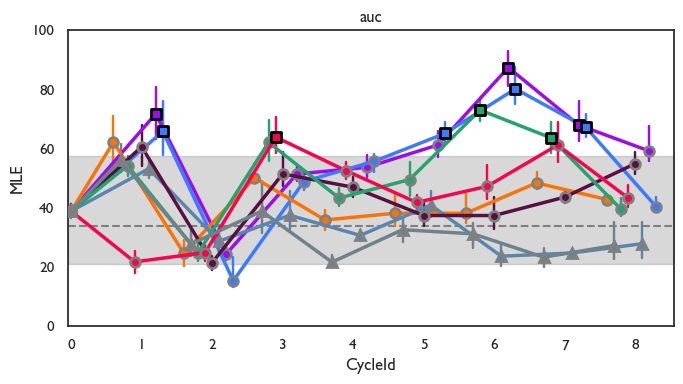

In [93]:
parameter = "ic50"
plotting_order = list(range(9))

y_lims_dict = {
    "ic50": (0, 0.08),
    "e_max": (75, 135),
    "e_min": (0, 50),
    "b": (0, 10),
    "auc": (0, 100)
}

# D1-m and D2-m use triangles; resistant replicates use circles
replicate_marker_map = {
    "D1-m": "^",
    "D2-m": "^",
    "R1-m": "o",
    "R2-m": "o",
    "R3-m": "o",
    "R4-m": "o",
    "R5-m": "o",
    "R6-m": "o"
}

for parameter in ["ic50", "e_max", "e_min", "b", "auc"]:

    # Plot the mean and 95% CI for each cell line
    curr_df = params_df[
        (params_df.Parameter == parameter) &
        (params_df.CycleId.isin(plotting_order))
    ].copy()

    curr_df = curr_df.reset_index(drop=True)

    curr_df_bootstraps = params_df_bootstraps[
        (params_df_bootstraps.Parameter == parameter) &
        (params_df_bootstraps.CycleId.isin(plotting_order))
    ].copy()

    curr_df_bootstraps = curr_df_bootstraps.reset_index(drop=True)

    # Add an x-shift to the data for better visualization
    for i, replicate_name in enumerate(
        curr_df_bootstraps.ReplicateName.unique()
    ):

        curr_df.loc[
            (curr_df.ReplicateName == replicate_name) &
            (curr_df.CycleId > 0),
            "CycleId"
        ] += (i + 1) * 0.1 - 0.5

        curr_df_bootstraps.loc[
            (curr_df_bootstraps.ReplicateName == replicate_name) &
            (curr_df_bootstraps.CycleId > 0),
            "CycleId"
        ] += (i + 1) * 0.1 - 0.5

    fig, ax = plt.subplots(
        1,
        1,
        figsize=(7, 4)
    )

    # Plot the MLE estimate for the parameter
    sns.lineplot(
        x="CycleId",
        y="MLE",
        hue="ReplicateName",
        style="ReplicateName",
        linewidth=2.5,
        palette=replicate_palette,
        markers=replicate_marker_map,
        dashes=False,
        markersize=7,
        markeredgewidth=2,
        markeredgecolor="grey",
        zorder=10,
        data=curr_df,
        ax=ax
    )

    # Annotate parameters that are significantly different from controls
    for replicate_name in curr_df.ReplicateName.unique():

        curr_df_replicate = curr_df[
            (curr_df.ReplicateName == replicate_name) &
            (curr_df.StatDifferent == True)
        ]

        ax.scatter(
            curr_df_replicate["CycleId"],
            curr_df_replicate["MLE"],
            color=replicate_palette[replicate_name],
            edgecolor="black",
            linewidth=2,
            marker="s",
            s=50,
            zorder=10
        )

    # Plot the 95% CI for each cell line based on bootstrap samples
    sns.lineplot(
        x="CycleId",
        y="Value",
        hue="ReplicateName",
        style="ReplicateName",
        errorbar=lambda x: np.array([
            x.quantile(
                (1 - significance_level_ci) / 2
            ),
            x.quantile(
                (1 + significance_level_ci) / 2
            )
        ]),
        err_kws={
            "linewidth": 1.75
        },
        err_style="bars",
        markers=replicate_marker_map,
        dashes=False,
        palette=replicate_palette,
        markersize=0,
        markeredgecolor="black",
        markeredgewidth=1,
        linestyle="none",
        data=curr_df_bootstraps,
        ax=ax
    )

    # -------------------------------------------------------------------------
    # Set tight x-axis limits based on shifted data
    # -------------------------------------------------------------------------
    x_min = min(
        curr_df["CycleId"].min(),
        curr_df_bootstraps["CycleId"].min()
    )

    x_max = max(
        curr_df["CycleId"].max(),
        curr_df_bootstraps["CycleId"].max()
    )

    x_left_padding = 0.05
    x_right_padding = 0.25

    ax.set_xlim(
        x_min - x_left_padding,
        x_max + x_right_padding
    )

    # Overlay band indicating 95% CI of the pretreatment value
    ic50_pre = curr_df_bootstraps[
        curr_df_bootstraps.ReplicateName.isin(
            ["D1-m", "D2-m"]
        )
    ]["Value"]

    lower_CI = ic50_pre.quantile(
        (1 - significance_level_ci) / 2
    )

    upper_CI = ic50_pre.quantile(
        (1 + significance_level_ci) / 2
    )

    x_lims = ax.get_xlim()

    ax.fill_between(
        x_lims,
        lower_CI,
        upper_CI,
        color="grey",
        alpha=0.3,
        zorder=0
    )

    ax.hlines(
        xmin=x_lims[0],
        xmax=x_lims[1],
        y=ic50_pre.mean(),
        color="grey",
        linestyle="--",
        zorder=1
    )

    # Remove legend
    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ax.set_ylim(
        y_lims_dict[parameter]
    )

    ax.set_xticks(plotting_order)
    ax.set_xticklabels(plotting_order)

    ax.set_xlabel("CycleId")
    ax.set_title(parameter)

    plt.tight_layout()

    plt.savefig(
        f"./figures/sotorasib_C0to8_{parameter}.png",
        dpi=1200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

Control n = 3 (C0 parental + C8 D1-m + C8 D2-m)
Control mean IC50 = 0.006594 μM
C8 resistant n = 6
C8 resistant mean IC50 = 0.033755 μM
Welch t-statistic = -4.7932
Welch t-test p-value = 3.9987e-03


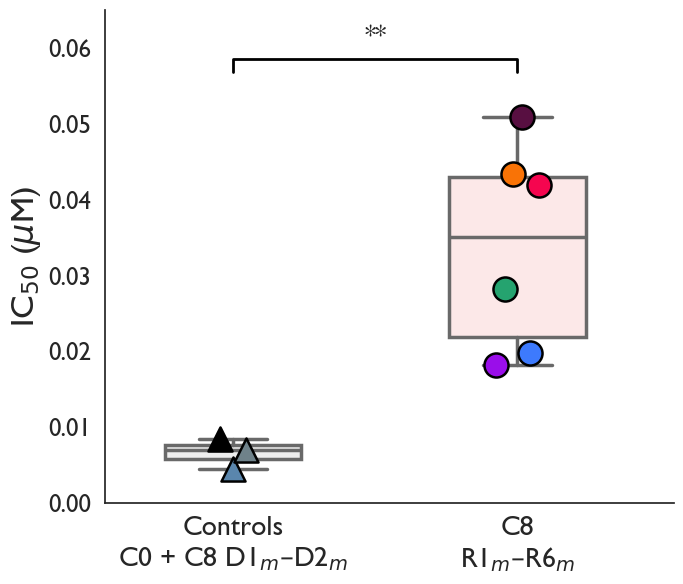

In [99]:
from scipy.stats import ttest_ind
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# Compare control IC50s with R1-m–R6-m at C8
# Controls = C0 parental + C8 D1-m + C8 D2-m
# =============================================================================

parameter = "ic50"

control_replicates = [
    "D1-m",
    "D2-m"
]

resistant_replicates = [
    "R1-m",
    "R2-m",
    "R3-m",
    "R4-m",
    "R5-m",
    "R6-m"
]

replicate_palette = {
    "D1-m": sns.xkcd_rgb["dusty blue"],
    "D2-m": sns.xkcd_rgb["steel grey"],
    "R1-m": sns.xkcd_rgb["violet"],
    "R2-m": sns.xkcd_rgb["teal green"],
    "R3-m": sns.xkcd_rgb["orange"],
    "R4-m": sns.xkcd_rgb["plum"],
    "R5-m": sns.xkcd_rgb["lightish blue"],
    "R6-m": sns.xkcd_rgb["pink red"]
}


# -------------------------------------------------------------------------
# Extract single parental C0 IC50
# -------------------------------------------------------------------------

cycle0_values = params_df[
    (params_df["Parameter"] == parameter) &
    (params_df["CycleId"] == 0)
]["MLE"].dropna()

cycle0_unique = cycle0_values.unique()

if len(cycle0_unique) != 1:
    raise ValueError(
        f"Expected one unique C0 parental IC50, "
        f"but found: {cycle0_unique}"
    )

cycle0_ic50 = cycle0_unique[0]


# -------------------------------------------------------------------------
# Extract C8 D1-m and D2-m control IC50s
# -------------------------------------------------------------------------

cycle8_control_df = (
    params_df[
        (params_df["Parameter"] == parameter) &
        (params_df["CycleId"] == 8) &
        (params_df["ReplicateName"].isin(control_replicates))
    ]
    .groupby("ReplicateName", as_index=False)["MLE"]
    .mean()
    .dropna(subset=["MLE"])
)

cycle8_control_df["ReplicateName"] = pd.Categorical(
    cycle8_control_df["ReplicateName"],
    categories=control_replicates,
    ordered=True
)

cycle8_control_df = (
    cycle8_control_df
    .sort_values("ReplicateName")
    .reset_index(drop=True)
)


# -------------------------------------------------------------------------
# Combine parental + C8 D1/D2 into control group
# -------------------------------------------------------------------------

control_df = pd.DataFrame({
    "ReplicateName": [
        "Parental",
        "D1-m",
        "D2-m"
    ],
    "MLE": [
        cycle0_ic50,
        cycle8_control_df.loc[
            cycle8_control_df["ReplicateName"] == "D1-m",
            "MLE"
        ].iloc[0],
        cycle8_control_df.loc[
            cycle8_control_df["ReplicateName"] == "D2-m",
            "MLE"
        ].iloc[0]
    ]
})


# -------------------------------------------------------------------------
# Extract one IC50 estimate for R1-m–R6-m at C8
# -------------------------------------------------------------------------

cycle8_df = (
    params_df[
        (params_df["Parameter"] == parameter) &
        (params_df["CycleId"] == 8) &
        (params_df["ReplicateName"].isin(resistant_replicates))
    ]
    .groupby("ReplicateName", as_index=False)["MLE"]
    .mean()
    .dropna(subset=["MLE"])
)

cycle8_df["ReplicateName"] = pd.Categorical(
    cycle8_df["ReplicateName"],
    categories=resistant_replicates,
    ordered=True
)

cycle8_df = (
    cycle8_df
    .sort_values("ReplicateName")
    .reset_index(drop=True)
)


# -------------------------------------------------------------------------
# Welch two-sample t-test
# -------------------------------------------------------------------------

t_statistic, p_value = ttest_ind(
    control_df["MLE"],
    cycle8_df["MLE"],
    equal_var=False,
    nan_policy="omit"
)

print(
    f"Control n = {len(control_df)} "
    f"(C0 parental + C8 D1-m + C8 D2-m)"
)

print(
    f"Control mean IC50 = "
    f"{control_df['MLE'].mean():.6f} μM"
)

print(
    f"C8 resistant n = {len(cycle8_df)}"
)

print(
    f"C8 resistant mean IC50 = "
    f"{cycle8_df['MLE'].mean():.6f} μM"
)

print(
    f"Welch t-statistic = {t_statistic:.4f}"
)

print(
    f"Welch t-test p-value = {p_value:.4e}"
)


# -------------------------------------------------------------------------
# Convert p-value to significance stars
# -------------------------------------------------------------------------

def p_to_stars(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return "ns"


sig_label = p_to_stars(p_value)


# -------------------------------------------------------------------------
# Plot
# -------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 6)
)


# -------------------------------------------------------------------------
# Left boxplot: parental + C8 D1-m + C8 D2-m
# -------------------------------------------------------------------------

ax.boxplot(
    control_df["MLE"],
    positions=[0],
    widths=0.48,
    patch_artist=True,
    showfliers=False,
    boxprops={
        "facecolor": "#EEEEEE",
        "edgecolor": "dimgray",
        "linewidth": 2.5
    },
    whiskerprops={
        "color": "dimgray",
        "linewidth": 2.5
    },
    capprops={
        "color": "dimgray",
        "linewidth": 2.5
    },
    medianprops={
        "color": "dimgray",
        "linewidth": 2.5
    }
)


# -------------------------------------------------------------------------
# Right boxplot: C8 R1-m–R6-m
# -------------------------------------------------------------------------

ax.boxplot(
    cycle8_df["MLE"],
    positions=[1],
    widths=0.48,
    patch_artist=True,
    showfliers=False,
    boxprops={
        "facecolor": "#FCE8E8",
        "edgecolor": "dimgray",
        "linewidth": 2.5
    },
    whiskerprops={
        "color": "dimgray",
        "linewidth": 2.5
    },
    capprops={
        "color": "dimgray",
        "linewidth": 2.5
    },
    medianprops={
        "color": "dimgray",
        "linewidth": 2.5
    }
)


# -------------------------------------------------------------------------
# Plot control points as triangles
# -------------------------------------------------------------------------

control_jitter = [
    -0.045,
    0,
    0.045
]

control_colors = {
    "Parental": "black",
    "D1-m": replicate_palette["D1-m"],
    "D2-m": replicate_palette["D2-m"]
}

for i, row in control_df.iterrows():

    replicate_name = row["ReplicateName"]
    y_value = row["MLE"]

    ax.scatter(
        control_jitter[i],
        y_value,
        s=300,
        marker="^",
        color=control_colors[replicate_name],
        edgecolor="black",
        linewidth=1.8,
        zorder=10
    )


# -------------------------------------------------------------------------
# Plot C8 resistant points as circles
# -------------------------------------------------------------------------

jitter = np.array([
    -0.075,
    -0.045,
    -0.015,
    0.015,
    0.045,
    0.075
])

for i, row in cycle8_df.iterrows():

    replicate_name = row["ReplicateName"]
    y_value = row["MLE"]
    x_value = 1 + jitter[i]

    ax.scatter(
        x_value,
        y_value,
        s=300,
        marker="o",
        color=replicate_palette[replicate_name],
        edgecolor="black",
        linewidth=1.8,
        zorder=10
    )


# -------------------------------------------------------------------------
# Add significance bracket
# -------------------------------------------------------------------------

data_max = max(
    control_df["MLE"].max(),
    cycle8_df["MLE"].max()
)

data_min = min(
    control_df["MLE"].min(),
    cycle8_df["MLE"].min()
)

data_range = data_max - data_min

if data_range == 0:
    data_range = 0.01

bracket_y = (
    data_max +
    0.13 * data_range
)

bracket_height = (
    0.035 * data_range
)

ax.plot(
    [0, 0, 1, 1],
    [
        bracket_y,
        bracket_y + bracket_height,
        bracket_y + bracket_height,
        bracket_y
    ],
    color="black",
    linewidth=2
)

ax.text(
    0.5,
    bracket_y +
    bracket_height +
    0.025 * data_range,
    sig_label,
    ha="center",
    va="bottom",
    fontsize=19,
    fontweight="bold"
)


# -------------------------------------------------------------------------
# Format axes
# -------------------------------------------------------------------------

ax.set_xlim(
    -0.45,
    1.55
)

ax.set_ylim(
    0,
    bracket_y +
    bracket_height +
    0.14 * data_range
)

ax.set_xlabel("")

ax.set_ylabel(
    r"IC$_{50}$ ($\mu$M)",
    fontsize=24
)

ax.set_xticks(
    [0, 1]
)

ax.set_xticklabels(
    [
        "Controls\nC0 + C8 D1$_m$–D2$_m$",
        "C8\nR1$_m$–R6$_m$"
    ],
    fontsize=20
)

ax.tick_params(
    axis="y",
    labelsize=18
)

sns.despine()

plt.tight_layout()


# -------------------------------------------------------------------------
# Save
# -------------------------------------------------------------------------

plt.savefig(
    "./figures/sotorasib_IC50_controls_vs_C8_R1toR6_boxplot.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "./figures/sotorasib_IC50_controls_vs_C8_R1toR6_boxplot.png",
    dpi=1200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

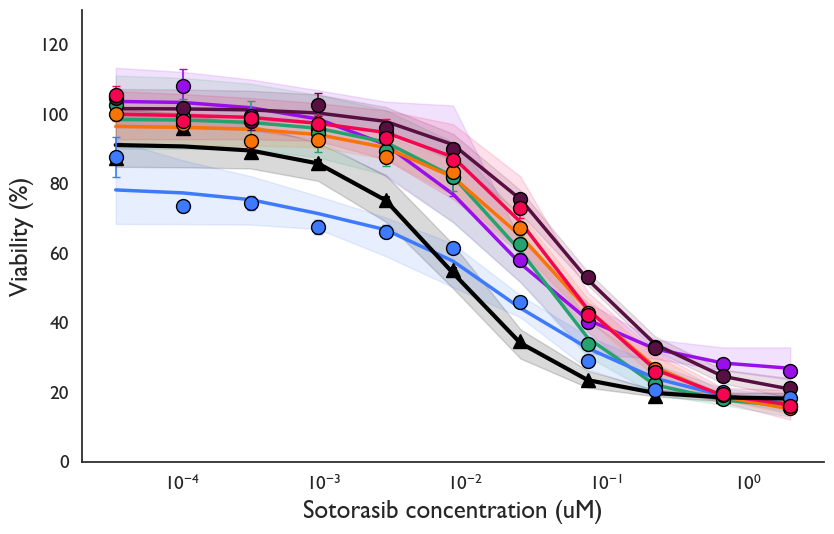

In [98]:
# =============================================================================
# Dose-response curves on one plot:
# C0 parental vs C8 R1-m to R6-m
# using bootstrap-fitted curves
# =============================================================================

plot_replicates = ["R1-m", "R2-m", "R3-m", "R4-m", "R5-m", "R6-m"]

lower_q = (1 - significance_level_ci) / 2
upper_q = (1 + significance_level_ci) / 2

# Make the figure slightly wider
fig, ax = plt.subplots(figsize=(8.5, 5.5))

# -----------------------------------------------------------------------------
# 1) Plot the pooled C0 parental bootstrap-fitted curve
# Since Cycle 0 is the same parental starting point, pool all C0 bootstrap fits
c0_boot = fit_df_bootstraps[
    fit_df_bootstraps["CycleId"] == 0
].copy()

c0_summary = (
    c0_boot
    .groupby("DrugConcentration")["Viability_cleaned"]
    .agg(
        median="median",
        lower=lambda x: x.quantile(lower_q),
        upper=lambda x: x.quantile(upper_q)
    )
    .reset_index()
    .sort_values("DrugConcentration")
)

# C0 raw data points:
# mean and SEM across all available C0 observations at each concentration
c0_points = (
    results_df_all[
        (results_df_all["CycleId"] == 0) &
        (results_df_all["DrugConcentration"] > 0) &
        (~results_df_all["Viability_cleaned"].isna())
    ]
    .groupby("DrugConcentration")["Viability_cleaned"]
    .agg(
        mean="mean",
        sem="sem"
    )
    .reset_index()
    .sort_values("DrugConcentration")
)

# Plot C0 bootstrap median curve
ax.plot(
    c0_summary["DrugConcentration"],
    c0_summary["median"],
    color="black",
    linewidth=3,
    zorder=5
)

# Plot C0 bootstrap confidence interval
ax.fill_between(
    c0_summary["DrugConcentration"],
    c0_summary["lower"],
    c0_summary["upper"],
    color="black",
    alpha=0.15,
    zorder=1
)

# Plot C0 observed points with SEM error bars
# C0 uses triangle markers
ax.errorbar(
    c0_points["DrugConcentration"],
    c0_points["mean"],
    yerr=c0_points["sem"],
    fmt="^",
    color="black",
    markerfacecolor="black",
    markeredgecolor="black",
    markersize=10,
    elinewidth=1.3,
    capsize=3,
    capthick=1.3,
    linestyle="none",
    zorder=6
)

# -----------------------------------------------------------------------------
# 2) Plot C8 R1-m to R6-m bootstrap-fitted curves
for replicate_name in plot_replicates:

    rep_boot = fit_df_bootstraps[
        (fit_df_bootstraps["ReplicateName"] == replicate_name) &
        (fit_df_bootstraps["CycleId"] == 8)
    ].copy()

    if rep_boot.empty:
        continue

    rep_summary = (
        rep_boot
        .groupby("DrugConcentration")["Viability_cleaned"]
        .agg(
            median="median",
            lower=lambda x: x.quantile(lower_q),
            upper=lambda x: x.quantile(upper_q)
        )
        .reset_index()
        .sort_values("DrugConcentration")
    )

    # Mean and SEM for observed C8 data
    rep_points = (
        results_df_all[
            (results_df_all["ReplicateName"] == replicate_name) &
            (results_df_all["CycleId"] == 8) &
            (results_df_all["DrugConcentration"] > 0) &
            (~results_df_all["Viability_cleaned"].isna())
        ]
        .groupby("DrugConcentration")["Viability_cleaned"]
        .agg(
            mean="mean",
            sem="sem"
        )
        .reset_index()
        .sort_values("DrugConcentration")
    )

    # Fitted bootstrap median curve
    ax.plot(
        rep_summary["DrugConcentration"],
        rep_summary["median"],
        color=replicate_palette[replicate_name],
        linewidth=2.5,
        zorder=4
    )

    # Shaded bootstrap confidence interval
    ax.fill_between(
        rep_summary["DrugConcentration"],
        rep_summary["lower"],
        rep_summary["upper"],
        color=replicate_palette[replicate_name],
        alpha=0.12,
        zorder=1
    )

    # Observed data points with SEM error bars
    ax.errorbar(
        rep_points["DrugConcentration"],
        rep_points["mean"],
        yerr=rep_points["sem"],
        fmt="o",
        color=replicate_palette[replicate_name],
        markerfacecolor=replicate_palette[replicate_name],
        markeredgecolor="black",
        markeredgewidth=1,
        markersize=10,
        elinewidth=1.2,
        capsize=3,
        capthick=1.2,
        linestyle="none",
        zorder=6
    )

# -----------------------------------------------------------------------------
# 3) Format plot
ax.set_xscale("log")
ax.set_xlabel("Sotorasib concentration (uM)", fontsize=18)
ax.set_ylabel("Viability (%)", fontsize=18)

ax.tick_params(
    axis="both",
    labelsize=14
)

ax.set_ylim(0, 130)

# Replicate labels and legend removed

sns.despine()
plt.tight_layout()

# -----------------------------------------------------------------------------
# 4) Save figures
plt.savefig(
    "./figures/sotorasib_drc_C0_vs_C8_R1toR6_bootstrap.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "./figures/sotorasib_drc_C0_vs_C8_R1toR6_bootstrap.png",
    dpi=1200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)